# Singular Value Decomposition for Satellite Images

This notebook applies SVD to 256×256 satellite image patches of three terrain types:
- **Urban** - `denseresidential04.tif`
- **Forest** - `forest04.tif`
- **Water / beach** - `beach04.tif`

Each image is converted to grayscale and treated as a matrix $A \in \mathbb{R}^{m \times n}$.
SVD factors it as $A = U \Sigma V^\top$. Rank-$k$ reconstructions keep only the $k$ largest singular values:

$$
A_k = U_{:,1:k}\,\Sigma_{1:k,1:k}\,V_{1:k,:}
$$

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

%matplotlib inline

In [ ]:
def load_grayscale_matrix(path):
    """Load an image, convert to grayscale, and return it as a matrix."""
    img = Image.open(path)
    imggray = img.convert('L')
    # Flatten pixel values into a 1-D array, then reshape to image size
    imgmat = np.array(list(imggray.getdata(band=0)), float)
    imgmat.shape = (imggray.size[1], imggray.size[0])
    imgmat = np.matrix(imgmat)
    return imgmat


def reconstruct(U, sigma, V, j, i):
    """Rank-(i-j) reconstruction using singular values with indices [j, i)."""
    return np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])

## 1. SVD Introduction & Eigen Value Selection

We start with the urban scene. After computing the SVD, we inspect the decay of the singular values (`sigma`) and compare reconstructions for several values of $k$.

In [ ]:
# Load urban satellite image and compute its SVD
imgmat = load_grayscale_matrix('denseresidential04.tif')
U, sigma, V = np.linalg.svd(imgmat)

print('Image shape:', imgmat.shape)
print('Number of singular values:', len(sigma))
print('First five singular values:', np.round(sigma[:5], 1))

Image shape: (256, 256)
Number of singular values: 256
First five singular values: [27212.7  6565.5  5938.2  4795.6  4182.8]


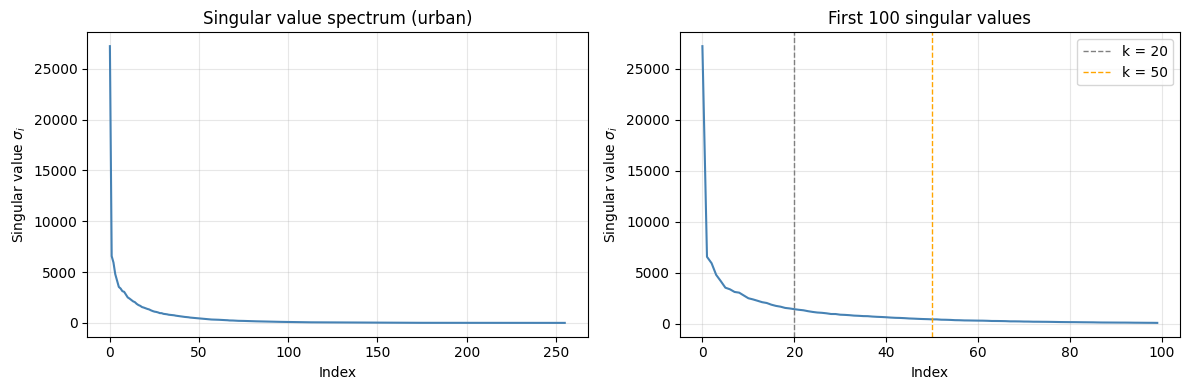

In [ ]:
# Decay of singular values — look for an "elbow" where the curve flattens
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(sigma, color='steelblue')
axes[0].set_xlabel('Index')
axes[0].set_ylabel(r'Singular value $\sigma_i$')
axes[0].set_title('Singular value spectrum (urban)')
axes[0].grid(True, alpha=0.3)

# Zoom on the first 100 values to see the elbow more clearly
axes[1].plot(sigma[:100], color='steelblue')
axes[1].axvline(20, color='gray', linestyle='--', linewidth=1, label='k = 20')
axes[1].axvline(50, color='orange', linestyle='--', linewidth=1, label='k = 50')
axes[1].set_xlabel('Index')
axes[1].set_ylabel(r'Singular value $\sigma_i$')
axes[1].set_title('First 100 singular values')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

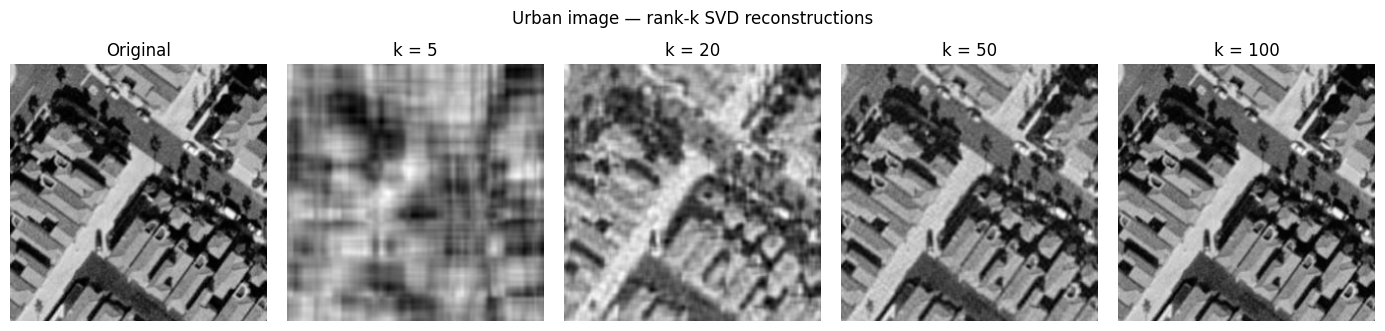

In [ ]:
# Reconstruct with the k largest singular values for several choices of k
ks = [5, 20, 50, 100]

fig, axes = plt.subplots(1, len(ks) + 1, figsize=(14, 3.2))

axes[0].imshow(imgmat, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

for ax, k in zip(axes[1:], ks):
    recon = reconstruct(U, sigma, V, 0, k)
    ax.imshow(recon, cmap='gray')
    ax.set_title(f'k = {k}')
    ax.axis('off')

plt.suptitle('Urban image — rank-k SVD reconstructions', y=1.02)
plt.tight_layout()
plt.show()

### How many Eigen values are good enough?

The singular-value spectrum drops sharply in the first ~20 components and then flattens. Visually:
- **k = 5** — only a coarse brightness layout; buildings are unreadable.
- **k = 20** — main structures appear, but edges are soft and fine detail is missing.
- **k = 50** — the scene is already recognizable; residual blur is mild.
- **k = 100** — perceptually close to the original for this 256×256 patch.

For the urban image, **k ≈ 50** is a practical compromise (near the elbow and visually acceptable). Going toward **k ≈ 100** removes most remaining perceptual degradation, at the cost of keeping roughly twice as many components.

## 2. Impact of Discarding the Largest Eigenvalues

Instead of keeping $\sigma_1,\ldots,\sigma_k$, we now keep $\sigma_{11},\ldots,\sigma_{k+10}$ (indices 10 through $k+10$) and compare that reconstruction with the standard top-$k$ result for $k = 50$.

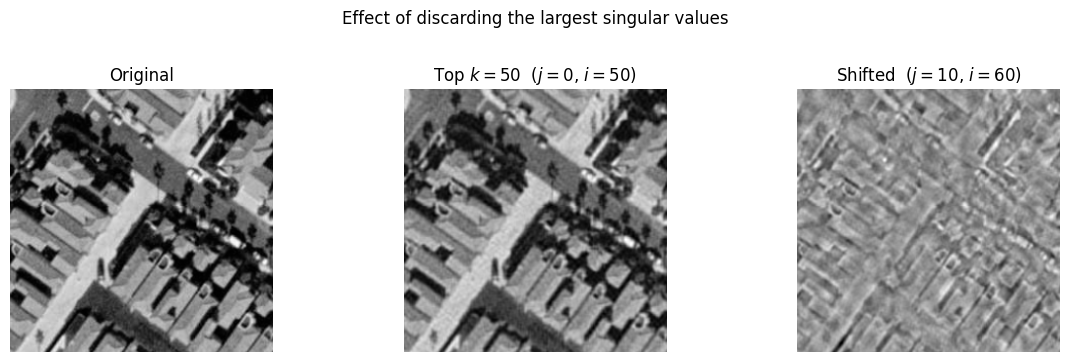

sigma[0]  = 27212.7  (dominant low-frequency / mean brightness term)
sigma[10] = 2504.5  (9.2% of sigma[0])


In [ ]:
k = 50

# Standard reconstruction: largest k singular values (indices 0 .. k)
recon_top_k = reconstruct(U, sigma, V, 0, k)

# Shifted reconstruction: skip the first 10 singular values (indices 10 .. k+10)
recon_shifted = reconstruct(U, sigma, V, 10, k + 10)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))

axes[0].imshow(imgmat, cmap='gray')
axes[0].set_title('Original')
axes[0].axis('off')

axes[1].imshow(recon_top_k, cmap='gray')
axes[1].set_title(r'Top $k=50$  ($j=0$, $i=50$)')
axes[1].axis('off')

axes[2].imshow(recon_shifted, cmap='gray')
axes[2].set_title(r'Shifted  ($j=10$, $i=60$)')
axes[2].axis('off')

plt.suptitle('Effect of discarding the largest singular values', y=1.02)
plt.tight_layout()
plt.show()

print(f'sigma[0]  = {sigma[0]:.1f}  (dominant low-frequency / mean brightness term)')
print(f'sigma[10] = {sigma[10]:.1f}  ({100 * sigma[10] / sigma[0]:.1f}% of sigma[0])')

### Instead of using the largest $k$ Eigen values, if you use the 10th, 11th, …, $k+10$ eigen values, would you get better images?

**No.** The result is clearly worse, not better.

Mathematically, the truncated SVD that keeps the **largest** singular values is the optimal rank-$k$ approximation in the Frobenius (and spectral) norm - Eckart–Young theorem. Any other set of $k$ components yields a larger reconstruction error.

Visually, the leading singular vectors capture the slowly varying background intensity (low spatial frequencies). Removing them subtracts that baseline brightness, so the image becomes an edge-like / embossed version dominated by mid- and high-frequency structure. Fine outlines may still be visible, but the natural appearance of the scene is lost.

Conclusion: always keep the largest singular values first; skipping them does not improve quality.

## 3. Terrain Complexity Analysis (Forest vs Urban vs Ocean/Water)

We compare how many singular values are needed for a perceptually faithful reconstruction across three terrain types that differ in spatial complexity.

In [ ]:
def show_terrain_svd(path, title, ks=(10, 50, 100)):
    """Load an image, run SVD, and display original + reconstructions for given k."""
    A = load_grayscale_matrix(path)
    U_loc, sigma_loc, V_loc = np.linalg.svd(A)

    fig, axes = plt.subplots(1, len(ks) + 1, figsize=(12, 2.8))

    axes[0].imshow(A, cmap='gray')
    axes[0].set_title(f'{title}\noriginal')
    axes[0].axis('off')

    for ax, k in zip(axes[1:], ks):
        recon = reconstruct(U_loc, sigma_loc, V_loc, 0, k)
        # Relative Frobenius error as a compact numeric check
        rel_err = np.linalg.norm(A - recon) / np.linalg.norm(A)
        ax.imshow(recon, cmap='gray')
        ax.set_title(f'k = {k}\nrel. error = {rel_err:.3f}')
        ax.axis('off')

    plt.tight_layout()
    plt.show()

    return sigma_loc

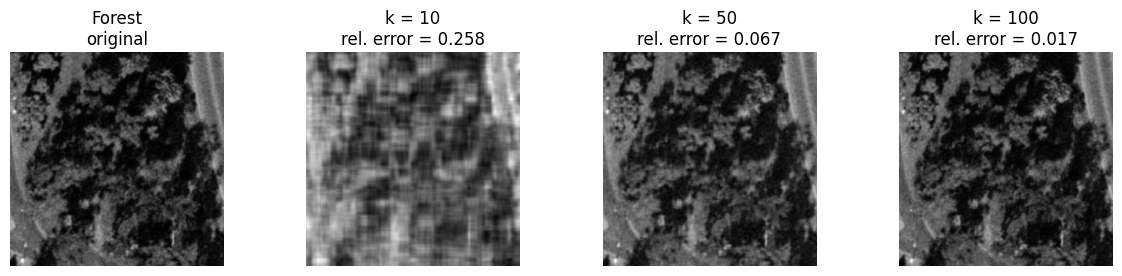

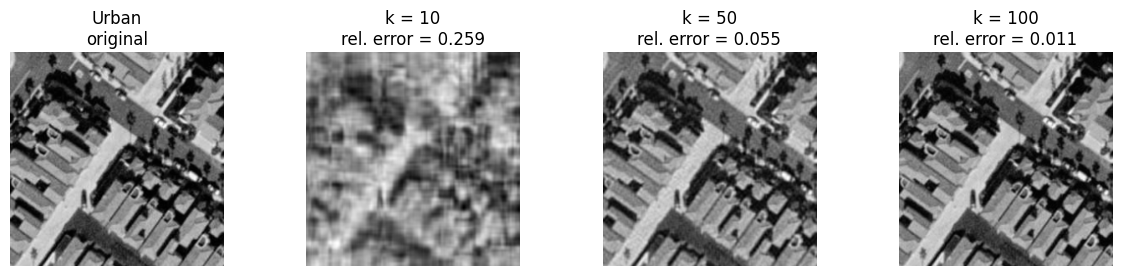

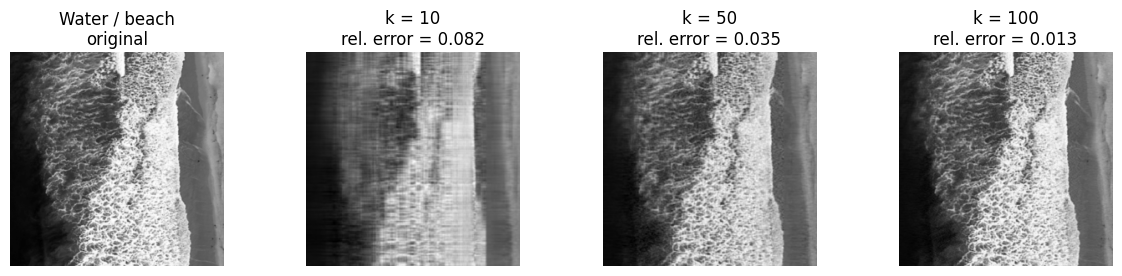

In [ ]:
sigma_forest = show_terrain_svd('forest04.tif', 'Forest')
sigma_urban = show_terrain_svd('denseresidential04.tif', 'Urban')
sigma_water = show_terrain_svd('beach04.tif', 'Water / beach')

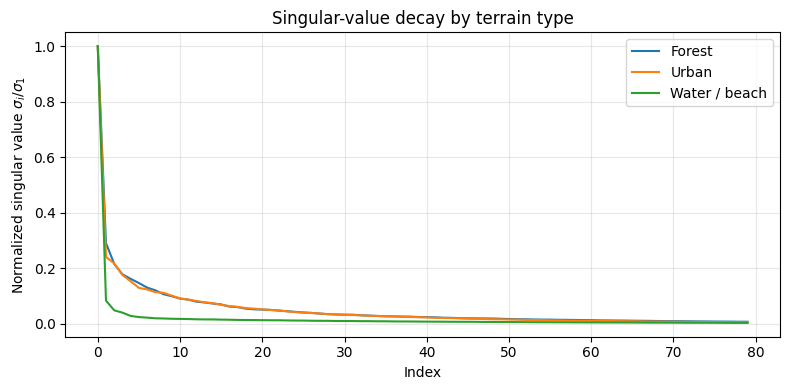

In [ ]:
# Compare singular-value decay across terrains (normalized by the largest value)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sigma_forest[:80] / sigma_forest[0], label='Forest')
ax.plot(sigma_urban[:80] / sigma_urban[0], label='Urban')
ax.plot(sigma_water[:80] / sigma_water[0], label='Water / beach')
ax.set_xlabel('Index')
ax.set_ylabel(r'Normalized singular value $\sigma_i / \sigma_1$')
ax.set_title('Singular-value decay by terrain type')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusions

### How many Eigen values are enough to capture the original image without perceptual degradation?

The answer depends strongly on **terrain complexity** (how much high-frequency spatial detail the scene contains):

| Terrain | Structure | Approx. $k$ for good perception |
|---|---|---|
| Water / beach | Large smooth regions, few sharp edges | **k ≈ 10–50** already looks close; low relative error even at small $k$ |
| Forest | Dense but fairly uniform texture | **k ≈ 50** recovers the overall look; finer canopy grain needs more |
| Urban | Dense edges, roofs, roads, shadows | **k ≈ 50–100**; small $k$ blurs building outlines |

Key observations:
1. **Detail density ↔ required $k$.** Homogeneous scenes (water) concentrate energy in the first few singular values, so a low-rank approximation preserves appearance. Structured scenes (urban) spread energy across many components that encode edges and local contrast.
2. **The spectrum confirms this.** After normalizing by $\sigma_1$, the water curve falls fastest; urban and forest decay more slowly, meaning later components still carry visible information.
3. **Skipping the largest singular values never helps.** Those terms encode global brightness / low frequencies. Dropping them produces an embossed, edge-only image with larger reconstruction error (Eckart–Young).
4. **Practical takeaway for satellite imagery.** SVD compression / denoising should choose $k$ from the singular-value elbow *and* a quick visual check. One fixed $k$ is not optimal for every land-cover class.

Overall, SVD is a compact way to separate coarse scene structure from fine detail and the number of components you need is a direct proxy for how complex the imaged terrain is.

AI tools were applied for formatting and plotting results.